In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('Datasets/ushape.csv')

In [3]:
df.head()

,X,Y,class
0,0.031595,0.986988,0.0
1,2.115098,-0.046244,1.0
2,0.882490,-0.075756,0.0
3,-0.055144,-0.037332,1.0
4,0.829545,-0.539321,1.0


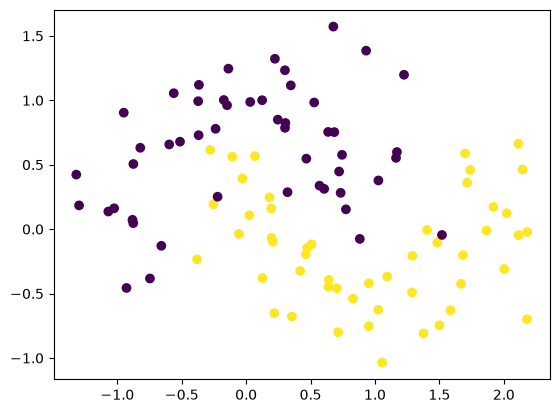

In [4]:
plt.scatter(df['X'],df['Y'],c=df['class'])

In [5]:
X = df.iloc[:,0:2].values
y = df.iloc[:,-1].values

In [6]:
import tensorflow
from tensorflow import keras
from keras import Sequential
from keras.layers import Dense

In [22]:
model = Sequential()

model.add(Dense(10,activation='tanh',input_dim=2))
model.add(Dense(10,activation='tanh'))
model.add(Dense(10,activation='tanh'))
model.add(Dense(10,activation='tanh'))
model.add(Dense(1,activation='sigmoid'))

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_7 (Dense)                      │ (None, 10)                  │              30 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_8 (Dense)                      │ (None, 10)                  │             110 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_9 (Dense)                      │ (None, 10)                  │             110 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_10 (Dense)                     │ (None, 10)                  │             110 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_11 (Dense)                     │ (None, 1)                   │              11 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 371 (1.45 KB)

 Trainable params: 371 (1.45 KB)

 Non-trainable params: 0 (0.00 B)

In [23]:
# Set parameters to 0
model.get_weights()

[array([[-0.31459993,  0.1551019 ,  0.07807285, -0.5338669 ,  0.29412335,
         -0.69027346,  0.5800852 , -0.646448  , -0.10833192,  0.39883894],
        [ 0.02164614, -0.37543654,  0.5443619 ,  0.59879345, -0.55074096,
          0.27905363,  0.52160496,  0.08788323, -0.5653634 , -0.54628164]],
       dtype=float32),
 array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0.], dtype=float32),
 array([[-0.5229379 ,  0.3796035 , -0.3359213 ,  0.43291706,  0.46868074,
         -0.44577235,  0.35606205,  0.4258361 ,  0.08395755,  0.27940065],
        [-0.5471754 , -0.25516602,  0.24480814, -0.00223017,  0.40674347,
          0.4359885 , -0.11517063, -0.08127606,  0.38466978, -0.54722553],
        [ 0.37660825,  0.20185041, -0.27248123, -0.36891103,  0.25713843,
         -0.18589133,  0.4406119 ,  0.52760434, -0.51089686, -0.17189577],
        [-0.18629432, -0.06381837,  0.16448456, -0.00592577,  0.35293776,
          0.40071034, -0.10257509, -0.06161079,  0.46833086, -0.01009727],
        [-0.43373

In [24]:
initial_weights = model.get_weights()

In [25]:
initial_weights[0] = np.random.randn(2,10)*np.sqrt(1/2)
initial_weights[1] = np.zeros(model.get_weights()[1].shape)
initial_weights[2] = np.random.randn(10,10)*np.sqrt(1/10)
initial_weights[3] = np.zeros(model.get_weights()[3].shape)
initial_weights[4] = np.random.randn(10,10)*np.sqrt(1/10)
initial_weights[5] = np.zeros(model.get_weights()[5].shape)
initial_weights[6] = np.random.randn(10,10)*np.sqrt(1/10)
initial_weights[7] = np.zeros(model.get_weights()[7].shape)
initial_weights[8] = np.random.randn(10,1)*np.sqrt(1/10)
initial_weights[9] = np.zeros(model.get_weights()[9].shape)

In [26]:
model.set_weights(initial_weights)

In [27]:
model.get_weights()

[array([[ 2.8793561e-01,  1.1445266e-03, -1.5500598e-01, -2.1441185e-01,
          1.2728924e-02, -4.6645212e-01,  1.8414198e-01,  9.4534594e-01,
          2.9725033e-01, -2.0185022e-01],
        [-4.0092313e-01,  3.4252968e-01,  1.1528765e+00,  8.1617242e-01,
         -2.4333343e-01, -8.9177847e-01,  5.4110348e-01,  3.3850390e-01,
         -1.7087065e+00,  5.4529703e-01]], dtype=float32),
 array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0.], dtype=float32),
 array([[-2.82602668e-01, -5.93832135e-02,  2.01251477e-01,
          2.36474246e-01, -4.03517544e-01, -2.83088125e-02,
          1.28085271e-01, -2.56184250e-01, -1.95285618e-01,
          1.00004040e-01],
        [ 3.80018294e-01, -4.17797327e-01, -2.96585052e-03,
          3.78626078e-01, -6.30592033e-02, -6.75931647e-02,
         -3.21178079e-01, -2.30604634e-01,  3.00083049e-02,
         -4.68908995e-01],
        [ 4.33565587e-01, -3.61876339e-01, -1.38651699e-01,
         -2.41480872e-01, -4.00866121e-01,  6.07181191e-01,
        

In [28]:
model.compile(loss='binary_crossentropy',optimizer='adam',metrics=['accuracy'])

In [ ]:
history = model.fit(X,y,epochs=100,validation_split=0.2)

Epoch 1/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 426ms/step - accuracy: 0.1375 - loss: 0.8495 - val_accuracy: 0.1500 - val_loss: 0.8481
Epoch 2/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - accuracy: 0.1375 - loss: 0.8227 - val_accuracy: 0.1000 - val_loss: 0.8200
Epoch 3/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 0.1500 - loss: 0.7981 - val_accuracy: 0.1500 - val_loss: 0.7933
Epoch 4/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 0.1500 - loss: 0.7748 - val_accuracy: 0.1500 - val_loss: 0.7679
Epoch 5/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 0.1500 - loss: 0.7529 - val_accuracy: 0.1500 - val_loss: 0.7438
Epoch 6/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - accuracy: 0.1750 - loss: 0.7323 - val_accuracy: 0.1500 - val_loss: 0.7209
Epoch 7/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 0.2375 - loss: 0.7129 - val_accuracy: 0.5000 - val_loss: 0.6992
Epoch 8/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 0.5125 - loss: 0.6945 - val_accuracy: 0.6500 - val_loss

In [ ]:
model.get_weights()

In [ ]:
from mlxtend.plotting import plot_decision_regions
import numpy as np
import matplotlib.pyplot as plt

class Wrapper:
    def __init__(self, model):
        self.model = model

    def predict(self, X):
        return (self.model.predict(X, verbose=0).ravel() >= 0.5).astype(int)

plot_decision_regions(
    np.asarray(X, dtype=float),
    np.asarray(y).ravel().astype(int),
    clf=Wrapper(model),
    legend=2
)
plt.show()

In [ ]:
(np.random.randn(10,10)*0.01).min()